In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import MemorySaver

In [2]:
from langgraph.graph.message import add_messages

class ChatState(TypedDict):

    messages: Annotated[list[BaseMessage], add_messages]


    # when we want to append messages in a list, 
    # use add_messages instead of operator.add

In [3]:
from dotenv import load_dotenv

from langchain_groq import ChatGroq
from langchain_google_genai import ChatGoogleGenerativeAI

load_dotenv()

True

In [4]:
# llm = ChatGoogleGenerativeAI(
#     model="gemini-3.6-flash",
#     temperature=0
# )
# from langchain_groq import ChatGroq

from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0
)


def chat_node(state: ChatState):

    # take user query from state
    messages = state['messages']

    # send to llm
    response = llm.invoke(messages)

    # response store state
    return {'messages': [response]}

In [7]:
checkpointer = MemorySaver()


graph = StateGraph(ChatState)

# add nodes
graph.add_node('chat_node', chat_node)

graph.add_edge(START, 'chat_node')
graph.add_edge('chat_node', END)

chatbot = graph.compile(checkpointer= checkpointer)

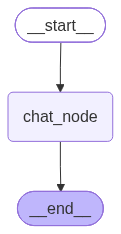

In [8]:
chatbot

In [9]:
def clean_response(text):
    return text.replace("\u202f", " ").strip()

In [10]:
# initial_state = {
#     'messages': [HumanMessage(content='What is the capital of india')]
# }

# chatbot.invoke(initial_state)['messages'][-1].content


In [12]:
from langchain_core.messages import HumanMessage

In [14]:
thread_id ='1'


while True:

    user_message =input('Type here: ')
    print('User:', user_message )


    if user_message.strip().lower() in ['exit','quit','bye']:
        break

    config ={'configurable':{'thread_id': thread_id}}


    response = chatbot.invoke({
    'messages': [HumanMessage(content=user_message)],
    }  ,config=config) 


    print('AI:', response['messages'][-1].content)

User: can you multipy 10 with 6
AI: Sure!  
\(10 \times 6 = 60\)
User: now ad 9 to it
AI: 60 + 9 = **69**.
User: waht is meaning of this in cult
AI: It sounds like you’re asking about the number **69** and how it’s used in cult‑oriented or esoteric contexts.  Here’s a quick rundown of the most common associations:

| Context | Typical meaning | Why it matters |
|---------|-----------------|----------------|
| **Occult numerology** | 69 is a “balanced” number – the digits 6 and 9 are mirror images, so it’s often seen as a symbol of duality, symmetry, or the union of opposites. | Many occult traditions use numbers to encode ideas about harmony, give‑and‑take, or the interplay of light and dark. |
| **Sexual symbolism** | 69 is famously the name of a sexual position that literally embodies mutual give‑and‑take. | Some fringe or cult‑like groups adopt it as a provocative symbol of intimacy, power dynamics, or the “perfect” exchange. |
| **Secret codes** | In a few cults or underground grou

In [15]:
chatbot.get_state(config= config)

StateSnapshot(values={'messages': [HumanMessage(content='hi', additional_kwargs={}, response_metadata={}, id='71cb8c46-7acc-49ec-b7cf-ebf3777b874a'), AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "hi". We need to respond. The instruction: "You are ChatGPT, a large language model trained by OpenAI." There\'s no special instruction. Just respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 57, 'prompt_tokens': 72, 'total_tokens': 129, 'completion_time': 0.063267527, 'completion_tokens_details': {'reasoning_tokens': 39}, 'prompt_time': 0.003392373, 'prompt_tokens_details': None, 'queue_time': 0.377193563, 'total_time': 0.0666599}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e11c8bbf69', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a022ca-1182-7ed0-b576-7b06ead9babb-0', tool_calls=[], invalid_tool_calls=[], usage_metada

In [16]:
state = chatbot.get_state(config)

messages = state.values["messages"]

for message in messages:
    if message.type == "human":
        print(f"\n👤 You: {message.content}")
    elif message.type == "ai":
        print(f"🤖 AI: {message.content}")


👤 You: hi
🤖 AI: Hello! How can I help you today?

👤 You: my name is aryan
🤖 AI: Nice to meet you, Aryan! How can I assist you today?

👤 You: can you tell me my name
🤖 AI: Sure! Your name is Aryan.

👤 You: 
🤖 AI: You’re right—your name is Aryan. Is there anything else you’d like to chat about or need help with?

👤 You: can you multipy 10 with 6
🤖 AI: Sure!  
\(10 \times 6 = 60\)

👤 You: now ad 9 to it
🤖 AI: 60 + 9 = **69**.

👤 You: waht is meaning of this in cult
🤖 AI: It sounds like you’re asking about the number **69** and how it’s used in cult‑oriented or esoteric contexts.  Here’s a quick rundown of the most common associations:

| Context | Typical meaning | Why it matters |
|---------|-----------------|----------------|
| **Occult numerology** | 69 is a “balanced” number – the digits 6 and 9 are mirror images, so it’s often seen as a symbol of duality, symmetry, or the union of opposites. | Many occult traditions use numbers to encode ideas about harmony, give‑and‑take, or the in